# Pareto Analysis of Steel Plate Defects

**Question:** Which defect types cause most of the problems on steel plates, and where should a quality team focus first?

**Data:** [UCI Steel Plates Faults](https://archive.ics.uci.edu/dataset/198/steel+plates+faults). It has 1,941 defects, and each one is labelled with one of 7 defect types.

**Method:** Pareto analysis. A Pareto chart sorts problems from most to least frequent and adds a cumulative percentage line. The tallest bars show the "vital few" causes that need attention first.

In [1]:
# Libraries
import pandas as pd                # tables
import matplotlib.pyplot as plt    # charts

## Load the data

The raw file has no header row. The column names are stored in a separate file, so we read them first.

In [2]:
column_names = open("data/Faults27x7_var").read().split()
df = pd.read_csv("data/Faults.NNA", sep=r"\s+", header=None, names=column_names)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (1941, 34)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


## Check the data

Before analysing, make sure the data can be trusted:
- Are there empty cells?
- Are there duplicate rows?
- Does every defect have **exactly one** defect type?

In [3]:
defect_types = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]

print("Empty cells:          ", df.isna().sum().sum())
print("Duplicate rows:       ", df.duplicated().sum())
print("Rows without 1 label: ", (df[defect_types].sum(axis=1) != 1).sum())

Empty cells:           0
Duplicate rows:        0
Rows without 1 label:  0


All three checks return 0, so the data is clean enough for this analysis.

## Step 1: Define the problem and its causes

- **Problem:** surface defects on steel plates.
- **Causes:** the 7 defect types.

In the raw data each defect type is its own 0/1 column. We turn them into one readable column called `defect_type`. `idxmax` picks the name of the column that holds the 1.

In [4]:
df["defect_type"] = df[defect_types].idxmax(axis=1)
df[["defect_type"]].head()

,defect_type
0,Pastry
1,Pastry
2,Pastry
3,Pastry
4,Pastry


## Step 2: Calculate the frequency of each cause

`value_counts()` counts how many times each defect type appears.

In [5]:
pareto = df["defect_type"].value_counts().reset_index()
pareto.columns = ["defect_type", "frequency"]
pareto

,defect_type,frequency
0,Other_Faults,673
1,Bumps,402
2,K_Scatch,391
3,Z_Scratch,190
4,Pastry,158
5,Stains,72
6,Dirtiness,55


## Step 3: Sort from highest to lowest

`value_counts()` already sorts, but we sort explicitly so the step is clear.

In [6]:
pareto = pareto.sort_values("frequency", ascending=False).reset_index(drop=True)

## Step 4: Plot a bar chart of the frequencies

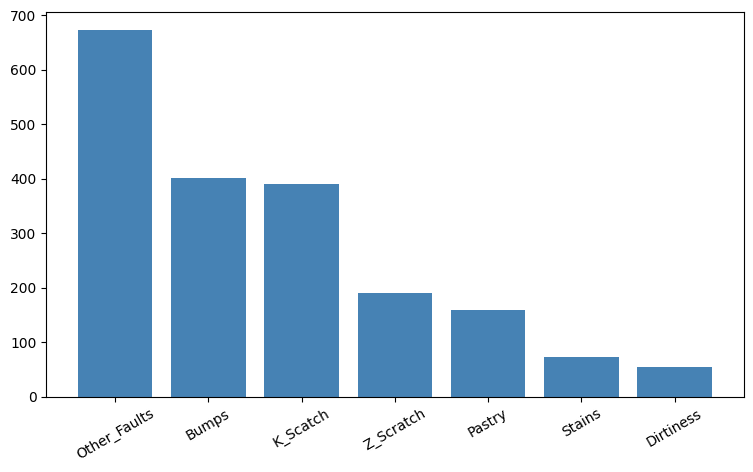

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(pareto["defect_type"], pareto["frequency"], color="steelblue")
plt.xticks(rotation=30)
plt.show()

## Step 5: Calculate the cumulative percentage

- **percentage** = frequency ÷ total × 100
- **cumulative percentage** = running total of the percentages (`cumsum`)

In [8]:
pareto["percentage"] = pareto["frequency"] / pareto["frequency"].sum() * 100
pareto["cumulative_percentage"] = pareto["percentage"].cumsum()
pareto.round(1)

,defect_type,frequency,percentage,cumulative_percentage
0,Other_Faults,673,34.7,34.7
1,Bumps,402,20.7,55.4
2,K_Scatch,391,20.1,75.5
3,Z_Scratch,190,9.8,85.3
4,Pastry,158,8.1,93.5
5,Stains,72,3.7,97.2
6,Dirtiness,55,2.8,100.0


## Steps 6 to 9: Add the cumulative line, labels and title

- **Step 6:** `ax.twinx()` creates a second y-axis on the right for the cumulative line.
- **Step 7:** the left axis is labelled "Frequency" and the right axis "Cumulative Percentage".
- **Step 8:** the x-axis is labelled "Defect Types".
- **Step 9:** the chart is titled "Pareto Chart of Steel Plate Defects".

The dashed line at 80% makes the "vital few" easy to see.

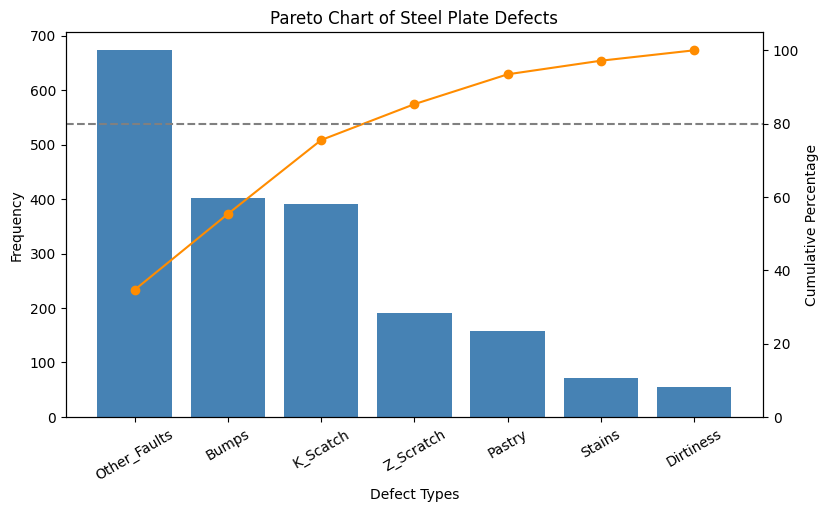

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

# Bars: frequency (left axis)
ax.bar(pareto["defect_type"], pareto["frequency"], color="steelblue")
ax.set_ylabel("Frequency")
ax.set_xlabel("Defect Types")
plt.xticks(rotation=30)

# Line: cumulative percentage (right axis)
ax2 = ax.twinx()
ax2.plot(pareto["defect_type"], pareto["cumulative_percentage"], color="darkorange", marker="o")
ax2.set_ylabel("Cumulative Percentage")
ax2.set_ylim(0, 105)
ax2.axhline(80, color="gray", linestyle="--")   # 80% reference line

plt.title("Pareto Chart of Steel Plate Defects")
plt.savefig("pareto_chart.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 10: Analyse the Pareto chart

Which defect types do we need to reach 80% of all defects?

In [10]:
# A type belongs to the "vital few" if the total before it was still under 80%
before = pareto["cumulative_percentage"] - pareto["percentage"]
vital_few = pareto[before < 80]
vital_few.round(1)

,defect_type,frequency,percentage,cumulative_percentage
0,Other_Faults,673,34.7,34.7
1,Bumps,402,20.7,55.4
2,K_Scatch,391,20.1,75.5
3,Z_Scratch,190,9.8,85.3


### Findings

1. **4 of the 7 defect types cause about 85% of all defects:** Other_Faults, Bumps, K_Scatch and Z_Scratch. A quality team should start with these.
2. **The 80/20 rule does not fit exactly here.** 4 of 7 types is 57% of the causes, not 20%. The Pareto principle is a guide, not a law. The key point still holds: a few causes create most of the problems.
3. **The biggest bar is "Other_Faults"**, a catch-all category (35% of defects). It does not tell us *what* went wrong. A sensible first action is to improve how these defects are recorded and split them into clearer types.
4. **Bumps and K_Scatch are the largest named defect types** (about 21% and 20%). They are the best candidates for a root-cause analysis such as 5 Whys.

### Limitation

Every row in this dataset is a defect, so we can compare defect types with each other. We cannot calculate a defect *rate*, because there is no count of good plates.

## Save the results for Power BI

These two files can be loaded into Power BI to build the same chart as a dashboard.

In [11]:
pareto.round(2).to_csv("pareto_table.csv", index=False)
df[["defect_type"]].to_csv("defects.csv", index_label="defect_id")
print("Saved pareto_table.csv and defects.csv")

Saved pareto_table.csv and defects.csv
